In [1]:
import sys; sys.path.append("..")
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from src.features import buat_fitur

d = pd.read_csv("../data/clean.csv", parse_dates=["waktu"], index_col="waktu")
d["lag_168"] = d["konsumsi_filled"].shift(168)

TRAIN_END = "2026-02-28 23:00"
VAL_START, VAL_END = "2026-03-01 00:00", "2026-04-30 23:00"
# test (Mei-Juni 2026) TIDAK disentuh di notebook ini

# hari "sulit": status libur berbeda dibanding 7 hari sebelumnya
beda_libur = d["hari_libur"] != d["hari_libur"].shift(168)

def laporan(nama, pred, y, mask):
    e = (pred - y)[mask]
    bl = beda_libur[mask]
    return {"model": nama, "n": int(mask.sum()),
            "MAE": e.abs().mean(),
            "MAE_minggu_biasa": e[~bl].abs().mean(),
            "MAE_minggu_libur": e[bl].abs().mean(),
            "bias": e.mean()}

y = d["konsumsi_kWh"]
in_val = (d.index >= VAL_START) & (d.index <= VAL_END)
rows = []

# baseline
mv = d["target_valid"] & d["lag_168"].notna() & in_val
rows.append(laporan("Baseline lag-168", d["lag_168"], y, mv))

# model A (tanpa lag) dan B (dengan lag)
for nama, pakai_lag in [("HGB A: tanpa lag", False), ("HGB B: dengan lag", True)]:
    X = buat_fitur(d, pakai_lag)
    ok = d["target_valid"] & X.notna().all(axis=1)
    tr = ok & (d.index <= TRAIN_END)
    va = ok & in_val
    m = HistGradientBoostingRegressor(loss="absolute_error", max_iter=400,
                                      learning_rate=0.05, early_stopping=False,
                                      random_state=0)
    m.fit(X[tr], y[tr])
    pred = pd.Series(m.predict(X), index=X.index)
    rows.append(laporan(nama, pred, y, va))

pd.DataFrame(rows).round(2)

,model,n,MAE,MAE_minggu_biasa,MAE_minggu_libur,bias
0,Baseline lag-168,1449,22.12,12.34,72.63,-0.33
1,HGB A: tanpa lag,1449,5.03,5.03,5.08,0.02
2,HGB B: dengan lag,1449,5.07,5.04,5.22,0.02


waktu
0     4.7
1     4.4
2     5.0
3     4.9
4     4.3
5     5.1
6     4.6
7     5.8
8     6.3
9     5.4
10    4.5
11    4.4
12    4.8
13    5.2
14    5.4
15    5.2
16    6.6
17    5.1
18    4.9
19    4.5
20    4.9
21    4.9
22    4.9
23    4.8
                mean  count
Akhir pekan     4.87    379
Hari kerja      5.12    952
Libur nasional  4.90    118


C:\Users\Danlion's\AppData\Local\Temp\ipykernel_8472\3815157811.py:20: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  tipe[d.index.dayofweek >= 5] = "Akhir pekan"


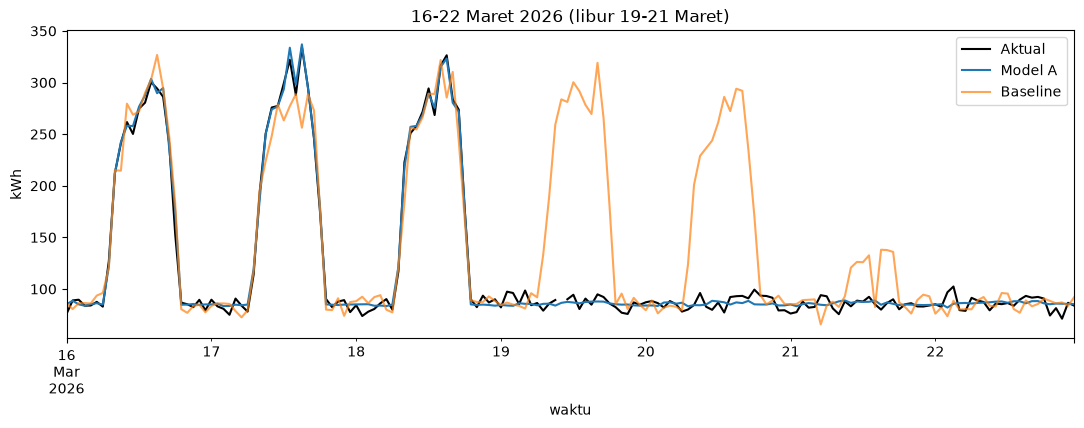

okupansi_orang         73.14
suhu_luar_C            10.13
jam                     1.98
kelembaban_luar_pct     0.00
bulan                  -0.00
hari_libur             -0.01
hari_minggu            -0.01
dtype: float64
MAE normal      : 5.03
MAE dengan derau: 9.66


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# refit Model A (supaya jelas model mana yang dianalisis)
XA = buat_fitur(d, False)
tr = d["target_valid"] & (d.index <= TRAIN_END)
va = d["target_valid"] & in_val
mA = HistGradientBoostingRegressor(loss="absolute_error", max_iter=400,
                                   learning_rate=0.05, early_stopping=False,
                                   random_state=0).fit(XA[tr], y[tr])
pred = pd.Series(mA.predict(XA), index=XA.index)
err = (pred - y)[va]

# 1. galat per jam
print(err.abs().groupby(err.index.hour).mean().round(1).to_string())

# 2. galat per tipe hari
tipe = pd.Series("Hari kerja", index=d.index)
tipe[d.index.dayofweek >= 5] = "Akhir pekan"
tipe[d["hari_libur"] == 1] = "Libur nasional"
print(err.abs().groupby(tipe[va]).agg(["mean", "count"]).round(2))

# 3. satu minggu yang memuat libur: aktual vs model vs baseline
w = slice("2026-03-16", "2026-03-22 23:00")
fig, ax = plt.subplots(figsize=(13, 4))
y[w].plot(ax=ax, label="Aktual", color="black")
pred[w].plot(ax=ax, label="Model A")
d["lag_168"][w].plot(ax=ax, label="Baseline", alpha=0.7)
ax.set_title("16-22 Maret 2026 (libur 19-21 Maret)"); ax.set_ylabel("kWh"); ax.legend()
plt.show()

# 4. fitur paling berpengaruh (permutation importance, pada validation)
r = permutation_importance(mA, XA[va], y[va], scoring="neg_mean_absolute_error",
                           n_repeats=5, random_state=0)
print(pd.Series(r.importances_mean, index=XA.columns).sort_values(ascending=False).round(2))

# 5. ketahanan terhadap prakiraan yang meleset (derau acak pada suhu dan okupansi)
rng = np.random.default_rng(0)
Xn = XA[va].copy()
Xn["suhu_luar_C"] += rng.normal(0, 1.5, len(Xn))
Xn["okupansi_orang"] = (Xn["okupansi_orang"] * rng.normal(1, 0.15, len(Xn))).clip(lower=0)
print("MAE normal      :", round((mA.predict(XA[va]) - y[va]).abs().mean(), 2))
print("MAE dengan derau:", round((mA.predict(Xn) - y[va]).abs().mean(), 2))